# Fase 1 · Adendo — Montagem informada pelo pesquisador, linha de massa e C9

> **Bases de dados usadas:**
> * **Dados do pesquisador:** respostas de 2026-11-20 (posições, ponteiras, dimensões da
>   Tabela 1 do TCC, rotação do tubo de FV), fotos da montagem (`docs/reports/fase1/fotos/`),
>   e os CSVs do conjunto de desenvolvimento (aço e Al ouro) e de `exp_5/`.
> * **Referências externas:** massas específicas nominais (aço 7850, Al 2700 kg/m³ —
>   `configs/data_sources.yaml`) e massa do PCB 352C33 (5,8 g, datasheet). Só para o modelo
>   de comparação da Seção 2.

O que o pesquisador informou:
* **2ª campanha (livre-livre):** dois acelerômetros perto das extremidades, na face superior
  (foto da barra); **sem ponto de impacto específico**. Longarina "90": um sensor na face
  superior, o outro na alma lateral (foto). "0°" = os dois sensores com a mesma orientação.
  FV alinhado: o ponto de golpe mudou entre repetições e o tubo girava um pouco.
* **1ª campanha:** biengastado → acelerômetro em L/2, impacto em L/4; engaste-livre →
  acelerômetro na ponta, impacto em L/4 do lado do acelerômetro.
* **Ponteiras:** metal e borracha, conforme o amortecimento do material (sem registro por
  ensaio). **Dimensões:** usar a Tabela 1 do TCC. **Ligas / certificados:** não existem;
  sensores calibrados (sensibilidade nominal).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.optimize import brentq

from dampid.analytic import beam
from dampid.eda import consistency as cs
from dampid.eda import quality as q
from dampid.io.catalog import load_catalog
from dampid.io.ni_csv import read_ni_csv

cat = load_catalog("data/catalog.yaml")
src = yaml.safe_load(open("configs/data_sources.yaml", encoding="utf-8"))
sv = pd.read_csv("data/processed/fase1_survey.csv")

## 1. Ponteira inferida pelo tempo de contato
Num contato de Hertz, a ponteira macia (borracha) dá um contato mais longo e uma banda de
força mais estreita que a metálica. Regra (`configs/qc_rules.yaml`): contato ≤ 3,5 ms → metal;
≥ 5 ms → borracha; entre os dois, indeterminado. A rigidez local da peça também influencia,
daí a faixa de folga.

In [2]:
c2 = sv[sv.campaign == 2]
tip = c2.groupby("config").F_width_ms.agg(["median", "min", "max"]).round(2)
tip["ponteira inferida"] = np.where(tip["median"] <= 3.5, "metal",
                                    np.where(tip["median"] >= 5.0, "borracha", "indeterminado"))
tip["f₋₁₀ mediana [Hz]"] = c2.groupby("config").F_f10db_hz.median().round(0)
print(tip.to_string())

                     median   min    max ponteira inferida  f₋₁₀ mediana [Hz]
config                                                                       
LL_ACO                 5.64  0.43   5.98          borracha              188.0
LL_ACRILICO            2.97  0.47  10.51             metal              627.0
LL_AL                  6.54  6.09   6.84          borracha              158.0
LL_FIB_CARBONO         3.12  3.01   3.48             metal              248.0
LL_FIB_VIDRO_0         6.45  5.90   7.38          borracha              150.0
LL_FIB_VIDRO_90        6.50  6.37   6.80          borracha              151.0
LL_PLA_CAVERNA         5.78  5.59   6.76          borracha              154.0
LL_PLA_LONGARINA_0     2.15  2.03   2.30             metal              464.0
LL_PLA_LONGARINA_90    2.07  1.99   2.27             metal              480.0


Leitura física: **borracha** nos espécimes de baixo amortecimento cujo 1º modo está abaixo
de ~200 Hz (aço, Al, FV, PLA caverna) — banda f₋₁₀ ≈ 150–190 Hz, energia concentrada onde
está o modo. **Metal** no acrílico, na fibra de carbono e nas longarinas — banda de 250–630
Hz, necessária para os modos mais altos (longarina ~490 Hz). Na fibra de carbono, a ponteira
metálica + golpe de ~40 N é a causa provável da saturação em 16/16 ensaios.

## 2. Linha de massa com a montagem real (barras livre-livre)
Modelo: viga de Euler–Bernoulli livre-livre (dimensões da Tabela 1, ρ nominal) com dois
conjuntos sensor de massa m_s nas posições 0,05 L e 0,95 L (fotos), resolvida por
Rayleigh–Ritz sobre os modos da viga nua (`dampid.analytic.beam.free_free_with_point_masses`,
testada contra as frequências analíticas). Para não misturar erro de rigidez com erro de
massa, EI é ajustado para o 1º modo do modelo cair na frequência medida. Comparação na faixa
40–120 Hz (entre a suspensão e o 1º modo) com a H1 média das repetições ouro.

* Impacto **no meio** (x_f = 0,5 L) prevê FRFs **iguais** nos dois sensores (simetria);
* impacto fora do meio prevê níveis diferentes (κ = 1 + 12 x_f x_r/L² muda de sinal entre as
  duas extremidades).

In [3]:
rows, curves = [], {}
for cfg, spec, f1m in [("LL_ACO", "ACO", 157.62), ("LL_AL", "AL", 152.01)]:
    es = [e for e in cat.by_config()[cfg] if e.file_class == "ouro"]
    d = cs.load_config(es)
    H = {k: d.h1(k)[0] for k in (0, 1)}
    f = d.f_hz
    g = src["specimens"][spec]["geometry"]
    L = g["L_mm"] / 1e3
    mb = src["specimens"][spec]["density_nominal"]["value"] * L * g["b_mm"] * g["h_mm"] * 1e-6
    band = (f >= 40) & (f <= 120)
    for ms in (0.006, 0.009, 0.012):
        for xf in (0.5, 0.4, 0.3):
            EI = brentq(lambda EI, ms=ms: beam.free_free_with_point_masses(
                L, mb, EI, [0.05, 0.95], [ms, ms])[0][2] - f1m, 1e-3, 1e3)
            fr, phi = beam.free_free_with_point_masses(L, mb, EI, [0.05, 0.95], [ms, ms])
            A = {k: beam.accelerance(f, fr, phi(xf)[0], phi(xr)[0])
                 for k, xr in ((0, 0.05), (1, 0.95))}
            r = {k: float(np.median(np.abs(H[k][band]) / np.abs(A[k][band]))) for k in (0, 1)}
            rows.append({"config": cfg, "m_viga [g]": round(mb * 1e3), "m_s [g]": ms * 1e3,
                         "x_f/L": xf, "medido/modelo (sensor em 0,05L)": round(r[0], 2),
                         "medido/modelo (sensor em 0,95L)": round(r[1], 2)})
            if ms == 0.009:
                curves[(cfg, xf)] = (f, H, A)
ml = pd.DataFrame(rows)
print(ml.to_string(index=False))

config  m_viga [g]  m_s [g]  x_f/L  medido/modelo (sensor em 0,05L)  medido/modelo (sensor em 0,95L)
LL_ACO         365      6.0    0.5                             1.24                             1.21
LL_ACO         365      6.0    0.4                             0.96                             1.98
LL_ACO         365      6.0    0.3                             0.86                             9.00
LL_ACO         365      9.0    0.5                             1.26                             1.23
LL_ACO         365      9.0    0.4                             0.99                             2.00
LL_ACO         365      9.0    0.3                             0.89                             8.20
LL_ACO         365     12.0    0.5                             1.29                             1.25
LL_ACO         365     12.0    0.4                             1.01                             2.02
LL_ACO         365     12.0    0.3                             0.91                        

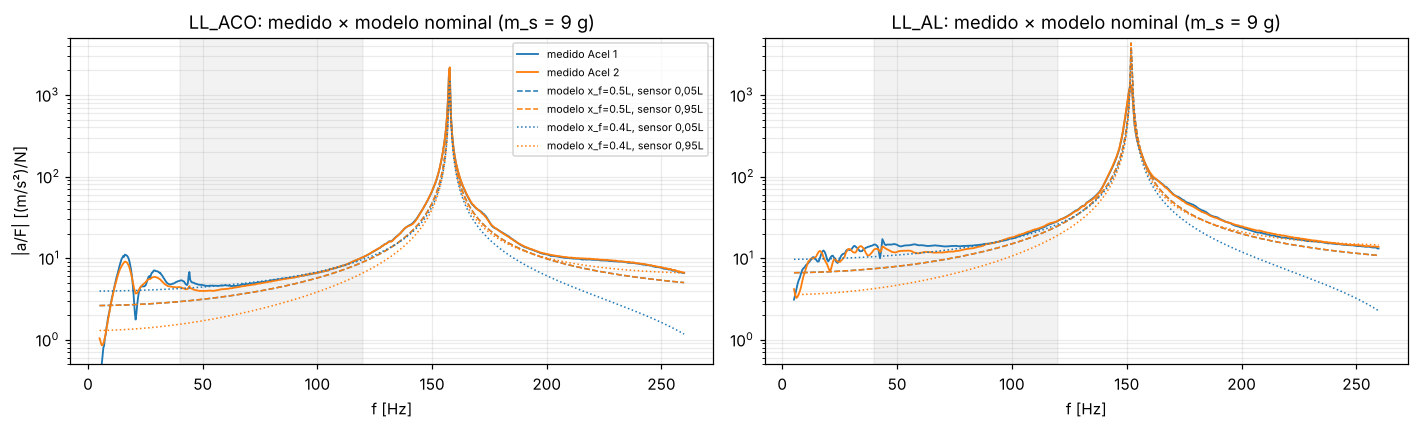

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, cfg in zip(axs, ["LL_ACO", "LL_AL"], strict=True):
    f, H, _ = curves[(cfg, 0.5)]
    sel = (f >= 5) & (f <= 260)
    for k in (0, 1):
        ax.semilogy(f[sel], np.abs(H[k][sel]), color=f"C{k}", lw=1.2, label=f"medido Acel {k + 1}")
    for xf, ls in [(0.5, "--"), (0.4, ":")]:
        _, _, A = curves[(cfg, xf)]
        for k in (0, 1):
            ax.semilogy(f[sel], np.abs(A[k][sel]), color=f"C{k}", ls=ls, lw=1,
                        label=f"modelo x_f={xf}L, sensor {'0,05' if k == 0 else '0,95'}L")
    ax.axvspan(40, 120, color="gray", alpha=0.1)
    ax.set_ylim(0.5, 5e3)
    ax.set_title(f"{cfg}: medido × modelo nominal (m_s = 9 g)")
    ax.set_xlabel("f [Hz]")
    ax.grid(True, which="both", alpha=0.25)
axs[0].set_ylabel("|a/F| [(m/s²)/N]")
axs[0].legend(fontsize=7)
plt.tight_layout()

Leitura: só o impacto **perto do meio** reproduz FRFs iguais nos dois sensores. Com x_f = 0,4 L
a razão medido/modelo já diverge 2× entre os sensores. "Sem ponto específico", na prática, foi
"por volta do meio" em todas as repetições. Isso é coerente com a coerência ≥ 0,99 entre
repetições e com o 2º modo (antissimétrico, nó no meio) quase não aparecer. Com impacto no
meio, o nível medido fica **~1,2–1,4× acima** do previsto com massas nominais, nos dois
sensores. A suspensão (modo de "pulo" em ~15–20 Hz, fora do modelo) explica +3 a +15 % na
faixa. O resto (~10–25 %) cabe na tolerância de sensibilidade nominal do martelo (±15 %,
pcb.com) e dos acelerômetros, ou em massa real menor que a nominal. **Só a pesagem separa as
duas coisas**; as unidades continuam confirmadas (um erro de unidade daria fator ≥ 9,8).

## 3. C9 — Input 1 e Input 2 da 1ª campanha no domínio da frequência
Na Etapa 1.2 o teste foi no tempo: razão de picos In1/In2 de 1,07 a 1,31. Mas a razão de
picos se mistura com a deriva lenta de base de um dos canais (acoplamento AC). O teste
decisivo é a **função de transferência In1/In2** (mesmo trecho, 5–300 Hz):
* se Input 1 fosse uma **resposta da estrutura** (aceleração em algum ponto), In1/In2 teria
  picos e vales de ressonância, como In0/In2 (dezenas de dB);
* se os dois forem **a mesma grandeza (força)**, In1/In2 é plana.

In [5]:
rows, spec = [], {}
for e in [x for x in cat.entries if x.campaign == 1]:
    r = read_ni_csv("data/raw/" + e.path)
    fs = r.fs_hz
    x = np.nan_to_num(r.data)
    P = q.find_pulses(x[1], fs)
    m = P[q.main_pulse(P)]
    n = min(int(1.5 * fs), x.shape[1] - m.i_start)
    f, T12 = q.quick_h1(x[2], x[1], fs, m.i_start, n)  # In1 / In2
    _, T02 = q.quick_h1(x[2], x[0], fs, m.i_start, n)  # In0 / In2
    b = (f > 5) & (f < 300)

    def span(h):
        db = 20 * np.log10(np.abs(h))
        return float(np.percentile(db, 95) - np.percentile(db, 5))

    alive = np.max(np.abs(x[2])) > 20 * q.robust_sigma(x[2])
    rows.append({"arquivo": e.id.replace("C1_", ""), "Input 2 com sinal": bool(alive),
                 "|In1/In2| mediana 5–300 Hz": round(float(np.median(np.abs(T12[b]))), 3) if alive else None,
                 "variação de |In1/In2| [dB] (p95−p5)": round(span(T12[b]), 1) if alive else None,
                 "variação de |In0/In2| [dB]": round(span(T02[b]), 1) if alive else None})
    spec[e.id] = (f, T12, T02, alive)
c9 = pd.DataFrame(rows)
with pd.option_context("display.width", 220):
    print(c9.to_string(index=False))
ok = c9.dropna()
print(f"\n|In1/In2| = {ok.iloc[:, 2].min():.3f}–{ok.iloc[:, 2].max():.3f} nos {len(ok)} arquivos com Input 2 ativo")

                      arquivo  Input 2 com sinal  |In1/In2| mediana 5–300 Hz  variação de |In1/In2| [dB] (p95−p5)  variação de |In0/In2| [dB]
       ACO_CC_mcentro_acentro               True                       1.137                                  0.8                        61.7
   ACO_CC_mforacentro_acentro               True                       1.148                                  0.4                        58.7
        ACO_CF_mcentro_aponta              False                         NaN                                  NaN                         NaN
         ACO_CF_mponta_aponta              False                         NaN                                  NaN                         NaN
  ACRILICO_CC_mcentro_acentro               True                       1.134                                  1.6                        33.9
ACRILICO_CC_mforaponta_aponta               True                       1.143                                  4.0                        31.9
   ACR

**Figura para o pesquisador** — para cada arquivo de `exp_5/`: (esq.) os três canais em torno
do golpe; (dir.) |In1/In2| e |In0/In2| entre 5 e 300 Hz.

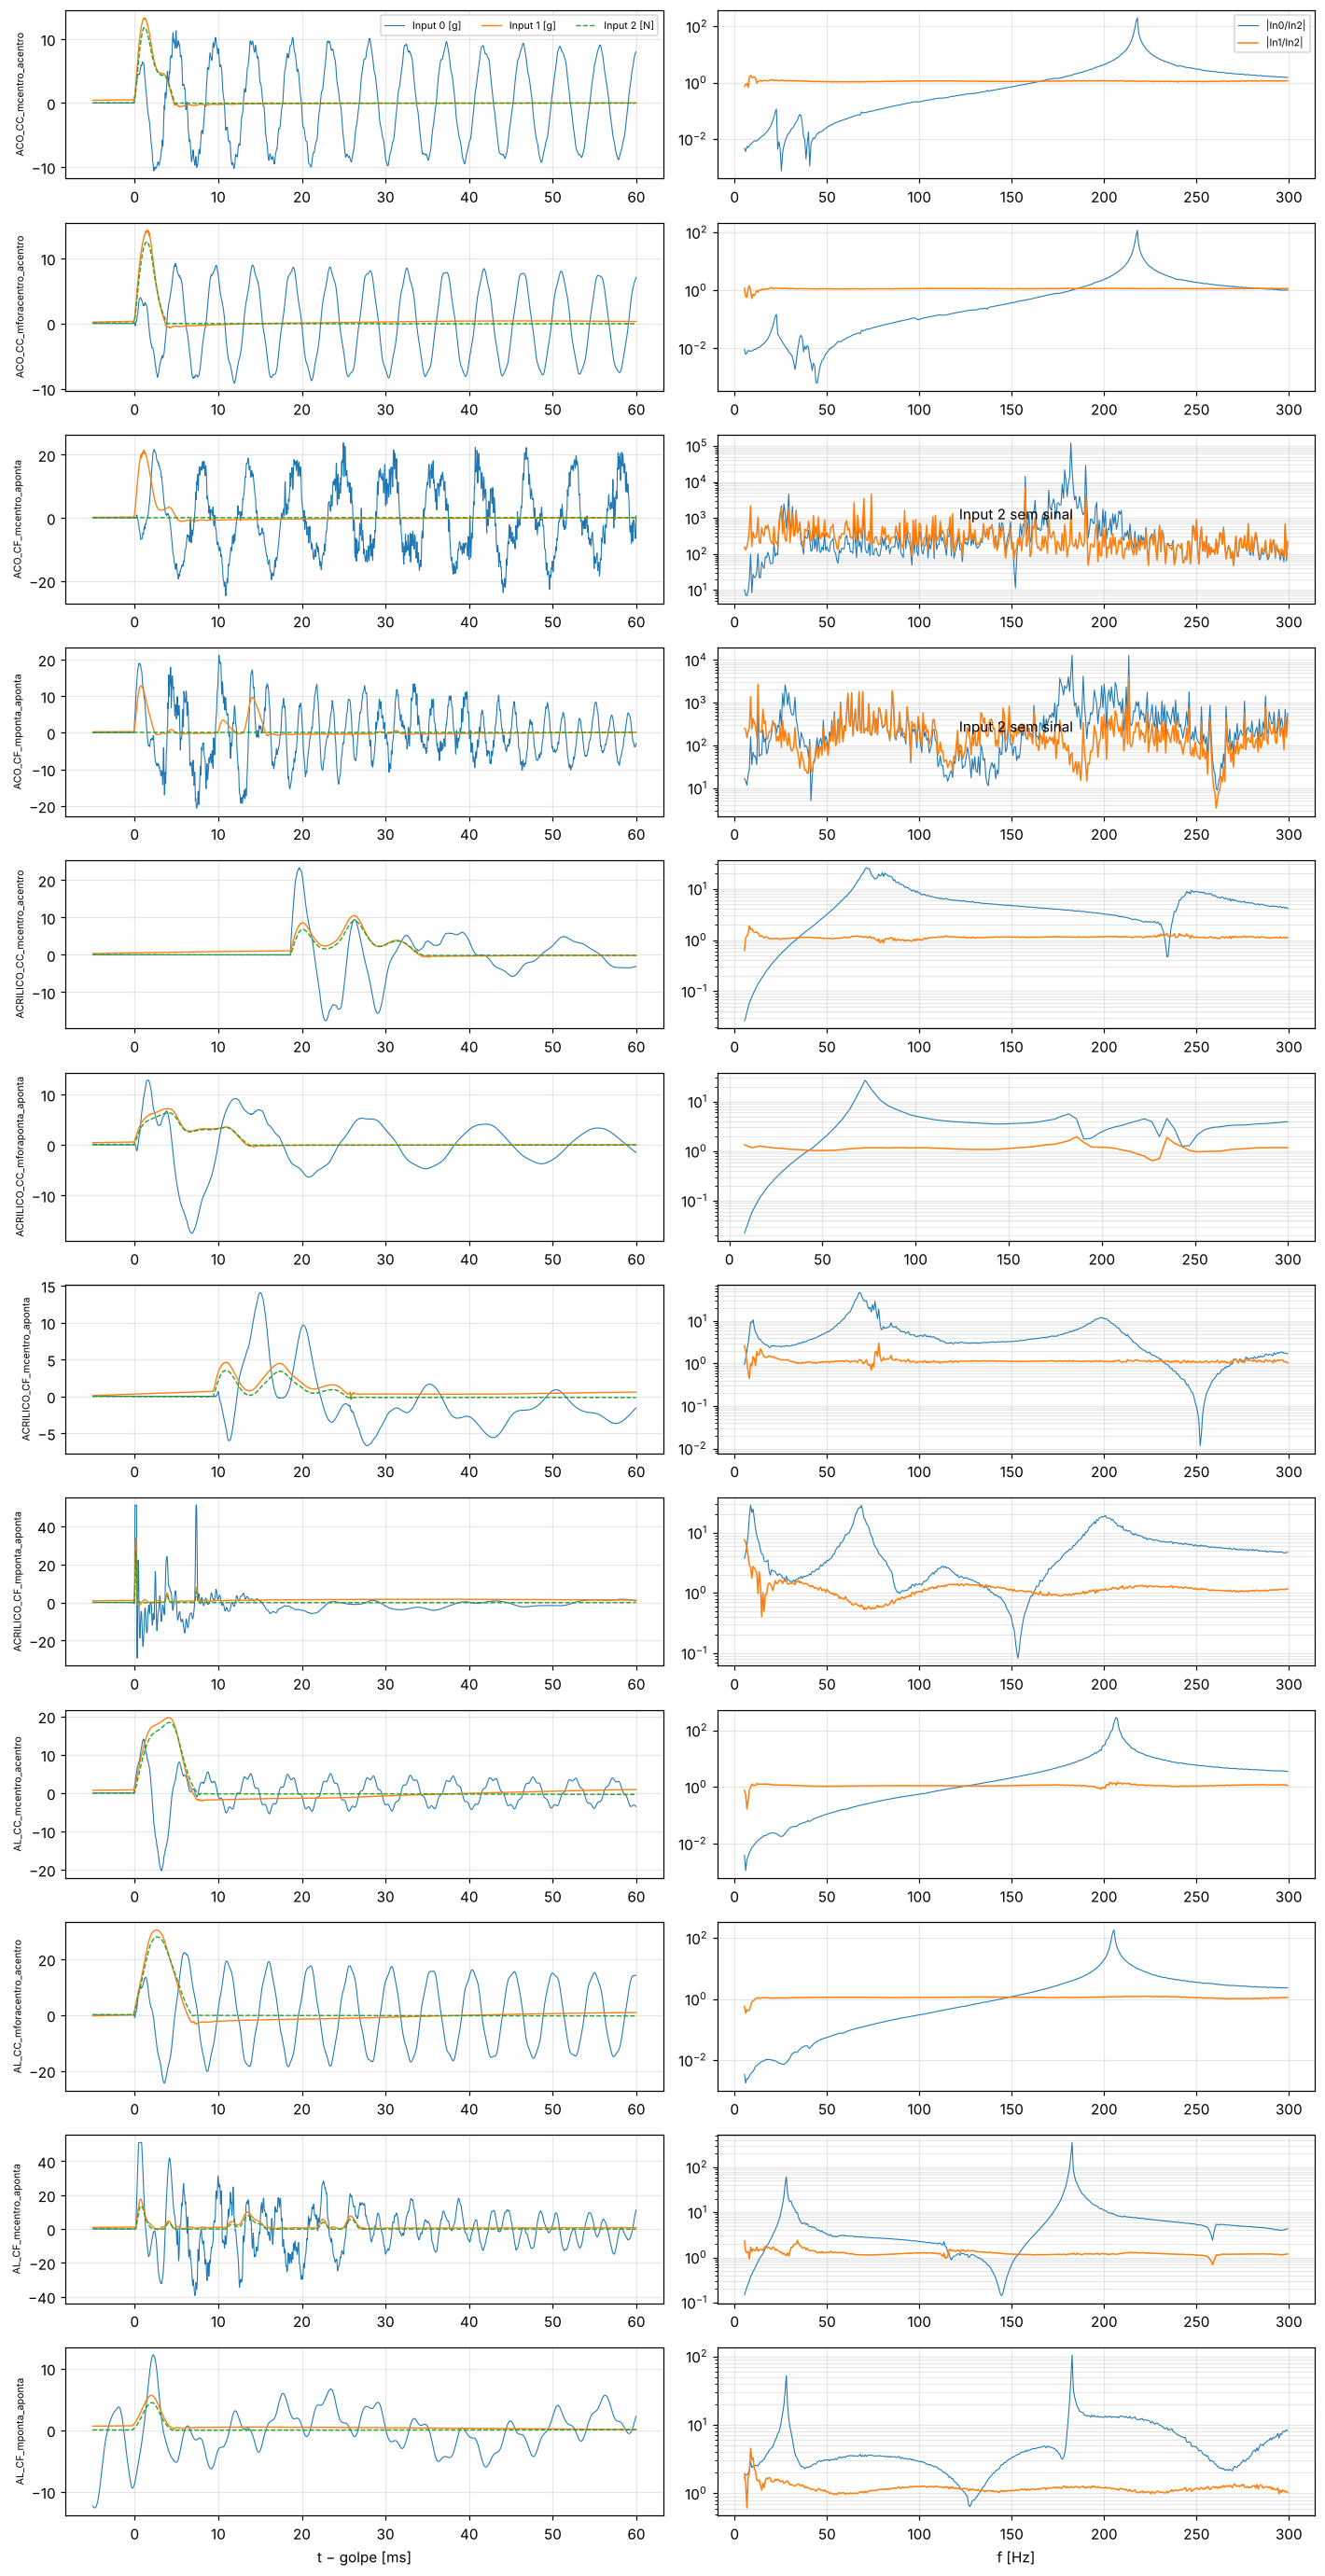

In [6]:
ids = [e.id for e in cat.entries if e.campaign == 1]
fig, axs = plt.subplots(len(ids), 2, figsize=(13, 2.1 * len(ids)))
for row, eid in zip(axs, ids, strict=True):
    e = next(x for x in cat.entries if x.id == eid)
    r = read_ni_csv("data/raw/" + e.path)
    fs = r.fs_hz
    P = q.find_pulses(np.nan_to_num(r.data[1]), fs)
    m = P[q.main_pulse(P)]
    sl = slice(max(0, m.i_start - int(5e-3 * fs)), m.i_start + int(60e-3 * fs))
    t = (np.arange(sl.stop - sl.start) - (m.i_start - sl.start)) / fs * 1e3
    row[0].plot(t, r.data[0][sl], lw=0.7, label="Input 0 [g]")
    row[0].plot(t, r.data[1][sl], lw=0.9, label="Input 1 [g]")
    row[0].plot(t, r.data[2][sl], lw=0.9, ls="--", label="Input 2 [N]")
    row[0].set_ylabel(eid.replace("C1_", ""), fontsize=7)
    row[0].grid(alpha=0.3)
    f, T12, T02, alive = spec[eid]
    b = (f > 5) & (f < 300)
    row[1].semilogy(f[b], np.abs(T02[b]), lw=0.7, color="C0", label="|In0/In2|")
    row[1].semilogy(f[b], np.abs(T12[b]), lw=1.0, color="C1", label="|In1/In2|")
    row[1].grid(True, which="both", alpha=0.3)
    if not alive:
        row[1].text(0.5, 0.5, "Input 2 sem sinal", transform=row[1].transAxes, ha="center")
axs[0, 0].legend(fontsize=7, ncol=3)
axs[0, 1].legend(fontsize=7)
axs[-1, 0].set_xlabel("t − golpe [ms]")
axs[-1, 1].set_xlabel("f [Hz]")
plt.tight_layout()

**Interpretação.** Input 0 é a resposta da estrutura: In0/In2 tem ressonâncias, com 20–64 dB
de variação. **Input 1 e Input 2 são a mesma grandeza, a força do martelo**: |In1/In2| é
plana em 5–300 Hz (variação de 0,4–4 dB; 7,8 dB só num arquivo de acrílico com o Input 0
saturado) e vale 1,12–1,20 em todos os arquivos com Input 2 ativo. O mesmo sinal do martelo
foi registrado duas vezes, com escalas de conversão diferentes em ~15 %. A hipótese H-a da
Etapa 1.2 ("mesmo sinal nas duas entradas") tinha sido rejeitada pela razão de picos no
tempo; essa rejeição foi forte demais, porque a deriva lenta de base do Input 1 distorce a
razão de picos. No aço engaste-livre só o Input 1 tem a força (o Input 2 estava sem sinal).

**Confirmado pelo pesquisador (2026-11-20): o martelo foi ligado nas duas entradas.**
Decisão D1.4: força = Input 2; no aço engaste-livre, Input 1 ÷ razão mediana
(`dampid.eda.c9`, aplicado no notebook 06).

Consequência: para ζ (que vem da forma da FRF), Input 1 e Input 2 dão o **mesmo resultado**.
A escala absoluta tem incerteza de ~15 %: qual dos dois está em N de verdade? O Input 2 tem
o rótulo N e dá velocidades de martelo plausíveis (Etapa 1.2). O legado usava o Input 1.